In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import requests

from pathlib import Path

# Load original building-level data
DATA_DIR = Path.cwd() / "data" / "processed"

buildings = pd.read_parquet(
    DATA_DIR / "buildings.parquet"
)

building_mentions = pd.read_parquet(
    DATA_DIR / "building_mentions.parquet"
)

# Filter Lower Manhattan buildings
df = buildings[
    buildings["in_lower_manhattan"] == True
].copy()

# Check duplicate BINs before deduplication
print("Rows after filtering:", len(df))
print("Unique BINs:", df["bin"].nunique())
print("Duplicate BINs:", df["bin"].duplicated().sum())

# Keep one record per building
df = df.drop_duplicates(subset="bin").copy()

print("Final Lower Manhattan buildings:", len(df))

# Prepare testing variables
df["n_test_pages"] = pd.to_numeric(
    df["n_test_pages"],
    errors="coerce"
).fillna(0)

df["has_testing"] = df["n_test_pages"] > 0

print("Buildings with testing:", df["has_testing"].sum())
print("Buildings without testing:", (~df["has_testing"]).sum())

Rows after filtering: 970
Unique BINs: 970
Duplicate BINs: 0
Final Lower Manhattan buildings: 970
Buildings with testing: 345
Buildings without testing: 625


In [2]:
# Extract existing BBL values if available
if "verified_bbl" in df.columns:
    df["verified_bbl"] = (
        df["verified_bbl"]
        .astype(str)
        .str.extract(r"(\d{10})")[0]
    )
else:
    df["verified_bbl"] = (
        df["bin"]
        .astype(str)
        .str.extract(r"(?i)^bbl:(\d{10})$")[0]
    )

# Find BINs without an existing BBL
bin_list = (
    df.loc[df["verified_bbl"].isna(), "bin"]
    .astype(str)
    .unique()
    .tolist()
)

# Match BINs using NYC Building Footprints
url = "https://data.cityofnewyork.us/resource/5zhs-2jue.json"

results = []

for i in range(0, len(bin_list), 200):
    batch = bin_list[i:i + 200]

    response = requests.get(
        url,
        params={
            "$select": "bin,base_bbl",
            "$where": f"bin in ({','.join(batch)})",
            "$limit": 50000
        },
        timeout=60
    )

    response.raise_for_status()
    results.extend(response.json())

crosswalk = pd.DataFrame(results)

if not crosswalk.empty:
    crosswalk["bin"] = crosswalk["bin"].astype(str)

    crosswalk["matched_bbl"] = (
        crosswalk["base_bbl"]
        .astype(str)
        .str.extract(r"(\d{10})")[0]
    )

    bin_to_bbl = (
        crosswalk[["bin", "matched_bbl"]]
        .drop_duplicates(subset="bin")
        .rename(columns={"bin": "bin_key"})
    )

    df["bin_key"] = df["bin"].astype(str)

    df = df.merge(
        bin_to_bbl,
        on="bin_key",
        how="left",
        validate="one_to_one"
    )

    df["verified_bbl"] = df["verified_bbl"].fillna(
        df["matched_bbl"]
    )

else:
    print("No additional BIN-to-BBL matches returned.")

print("Buildings with BBL:", df["verified_bbl"].notna().sum())
print("Buildings without BBL:", df["verified_bbl"].isna().sum())

Buildings with BBL: 970
Buildings without BBL: 0


In [3]:
# Extract Tax Block from BBL
df["verified_tax_block"] = (
    df["verified_bbl"].str[0]
    + "-"
    + df["verified_bbl"].str[1:6]
)

print("Total buildings:", df["bin"].nunique())
print("Buildings with Tax Block:",
      df["verified_tax_block"].notna().sum())
print("Buildings without Tax Block:",
      df["verified_tax_block"].isna().sum())

print("Unique Tax Blocks:",
      df["verified_tax_block"].nunique())

Total buildings: 970
Buildings with Tax Block: 970
Buildings without Tax Block: 0
Unique Tax Blocks: 126


,Metric,Value
0,Total Buildings,970
1,Buildings with Testing,345
2,Buildings without Testing,625
3,Total Building-linked Test-page Associations,2509
4,Overall Sample Testing Coverage,35.57%



Testing-page count summary:


count    970.000000
mean       2.586598
std       14.520731
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max      278.000000
Name: n_test_pages, dtype: float64

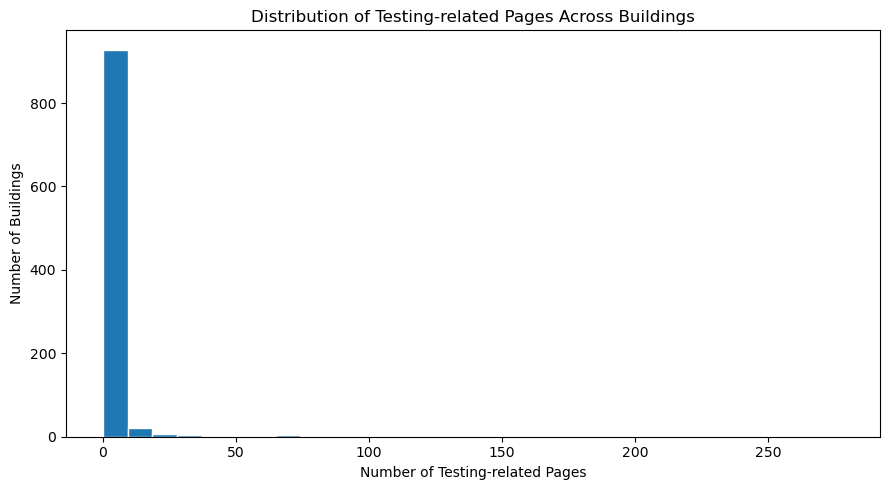

In [4]:
total_buildings = df["bin"].nunique()

tested_buildings = df.loc[
    df["has_testing"], "bin"
].nunique()

untested_buildings = total_buildings - tested_buildings

total_test_pages = df["n_test_pages"].sum()

overall_coverage = tested_buildings / total_buildings

overall_summary = pd.DataFrame({
    "Metric": [
        "Total Buildings",
        "Buildings with Testing",
        "Buildings without Testing",
        "Total Building-linked Test-page Associations",
        "Overall Sample Testing Coverage"
    ],
    "Value": [
        total_buildings,
        tested_buildings,
        untested_buildings,
        int(total_test_pages),
        f"{overall_coverage:.2%}"
    ]
})

display(overall_summary)

# Distribution of testing-related pages across buildings
print("\nTesting-page count summary:")
display(df["n_test_pages"].describe())

# Histogram
plt.figure(figsize=(9, 5))

plt.hist(
    df["n_test_pages"],
    bins=30,
    edgecolor="white"
)

plt.xlabel("Number of Testing-related Pages")
plt.ylabel("Number of Buildings")
plt.title("Distribution of Testing-related Pages Across Buildings")

plt.tight_layout()
plt.show()

In [5]:
block_testing_summary = (
    df.dropna(subset=["verified_tax_block"])
    .groupby("verified_tax_block")
    .agg(
        n_buildings=("bin", "nunique"),
        buildings_with_testing=("has_testing", "sum"),
        total_test_pages=("n_test_pages", "sum")
    )
    .reset_index()
)

# Calculate sample testing coverage
block_testing_summary["testing_coverage_rate"] = (
    block_testing_summary["buildings_with_testing"]
    / block_testing_summary["n_buildings"]
)

block_testing_summary = block_testing_summary.sort_values(
    "total_test_pages",
    ascending=False
)

print("Number of Tax Blocks:",
      block_testing_summary["verified_tax_block"].nunique())

display(block_testing_summary.head(20))

Number of Tax Blocks: 126


,verified_tax_block,n_buildings,buildings_with_testing,total_test_pages,testing_coverage_rate
12,1-00016,42,28,646,0.666667
111,1-00151,8,1,278,0.125000
91,1-00126,2,2,193,1.000000
92,1-00127,2,2,139,1.000000
102,1-00142,5,2,98,0.400000
90,1-00125,1,1,73,1.000000
35,1-00040,6,2,66,0.333333
67,1-00080,3,1,59,0.333333
56,1-00068,8,5,50,0.625000
65,1-00078,20,11,48,0.550000


In [7]:
# Load NYC Tax Block polygons
url = (
    "https://data.cityofnewyork.us/resource/"
    "akq4-haa2.geojson?$limit=50000"
)

blocks_geo = gpd.read_file(url)

# Standardize geographic identifiers
blocks_geo["boro"] = blocks_geo["boro"].astype(str)

blocks_geo["block"] = (
    pd.to_numeric(blocks_geo["block"])
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
)

blocks_geo["verified_tax_block"] = (
    blocks_geo["boro"] + "-" + blocks_geo["block"]
)

# Keep Manhattan
blocks_geo = blocks_geo[
    blocks_geo["boro"] == "1"
].copy()

print("Manhattan Tax Blocks:", len(blocks_geo))

# Match research Tax Blocks with geographic boundaries
research_blocks = blocks_geo.merge(
    block_testing_summary,
    on="verified_tax_block",
    how="inner"
)

print("Research Tax Blocks:",
      block_testing_summary["verified_tax_block"].nunique())

print("Matched Tax Blocks:",
      research_blocks["verified_tax_block"].nunique())

print(
    "Unmatched Tax Blocks:",
    len(
        set(block_testing_summary["verified_tax_block"])
        - set(research_blocks["verified_tax_block"])
    )
)

Manhattan Tax Blocks: 2935
Research Tax Blocks: 126
Matched Tax Blocks: 126
Unmatched Tax Blocks: 0


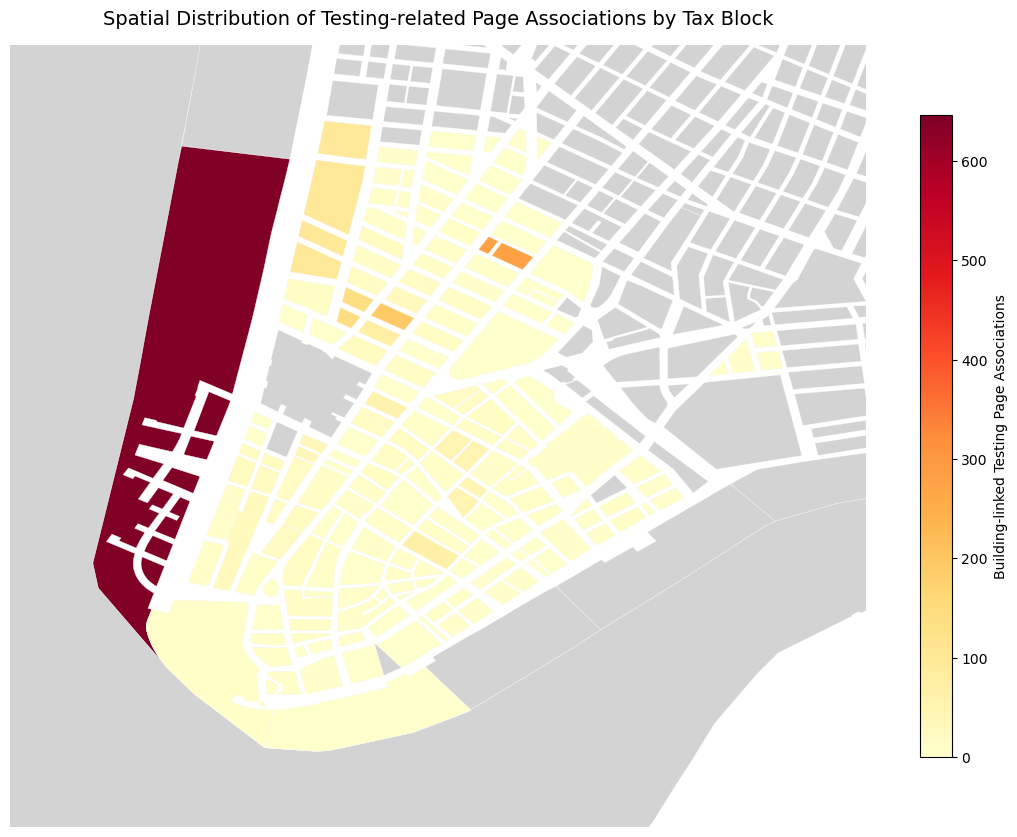

In [8]:
fig, ax = plt.subplots(figsize=(11, 11))

# Background: all Manhattan Tax Blocks
blocks_geo.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="white",
    linewidth=0.2
)

# Overlay: research Tax Blocks
research_blocks.plot(
    column="total_test_pages",
    cmap="YlOrRd",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label": "Building-linked Testing Page Associations",
        "shrink": 0.6
    },
    ax=ax
)

# Zoom into Lower Manhattan research area
xmin, ymin, xmax, ymax = research_blocks.total_bounds

x_margin = (xmax - xmin) * 0.12
y_margin = (ymax - ymin) * 0.12

ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)

ax.set_title(
    "Spatial Distribution of Testing-related Page Associations "
    "by Tax Block",
    fontsize=14,
    pad=15
)

ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout()
plt.show()

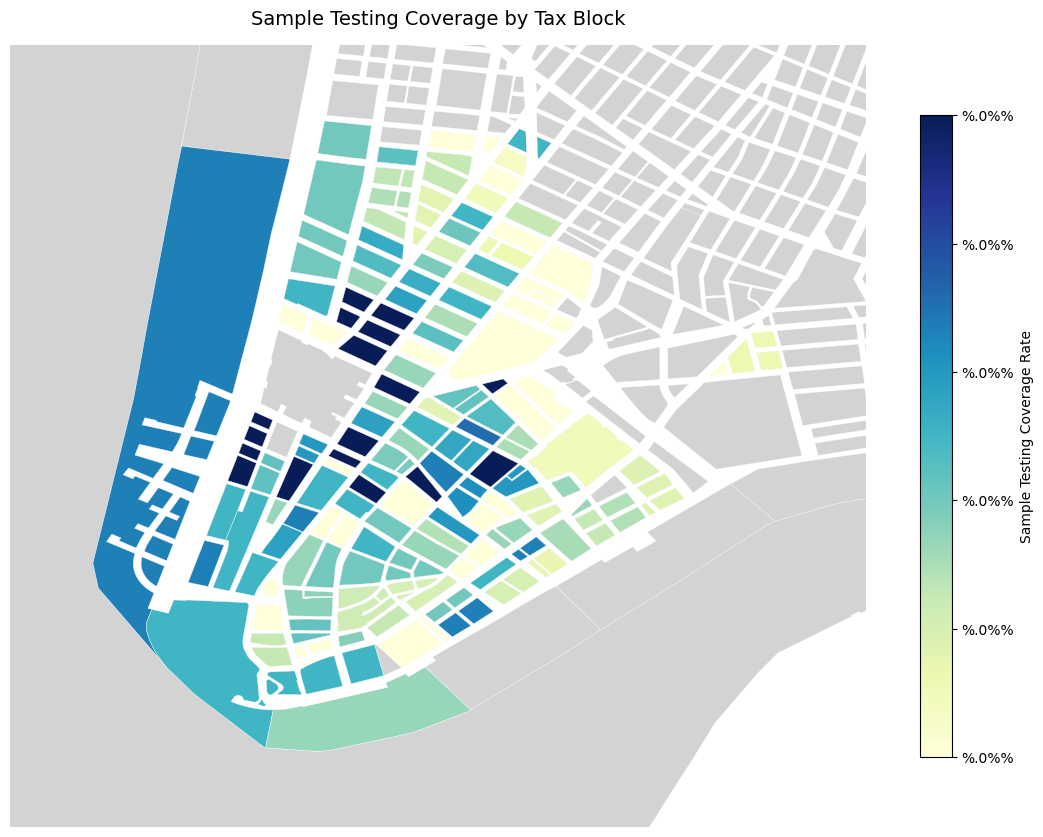

In [9]:
fig, ax = plt.subplots(figsize=(11, 11))

# Background: all Manhattan Tax Blocks
blocks_geo.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="white",
    linewidth=0.2
)

# Overlay: sample testing coverage
research_blocks.plot(
    column="testing_coverage_rate",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label": "Sample Testing Coverage Rate",
        "shrink": 0.6,
        "format": "%.0%%"
    },
    ax=ax
)

xmin, ymin, xmax, ymax = research_blocks.total_bounds

x_margin = (xmax - xmin) * 0.12
y_margin = (ymax - ymin) * 0.12

ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)

ax.set_title(
    "Sample Testing Coverage by Tax Block",
    fontsize=14,
    pad=15
)

ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout()
plt.show()

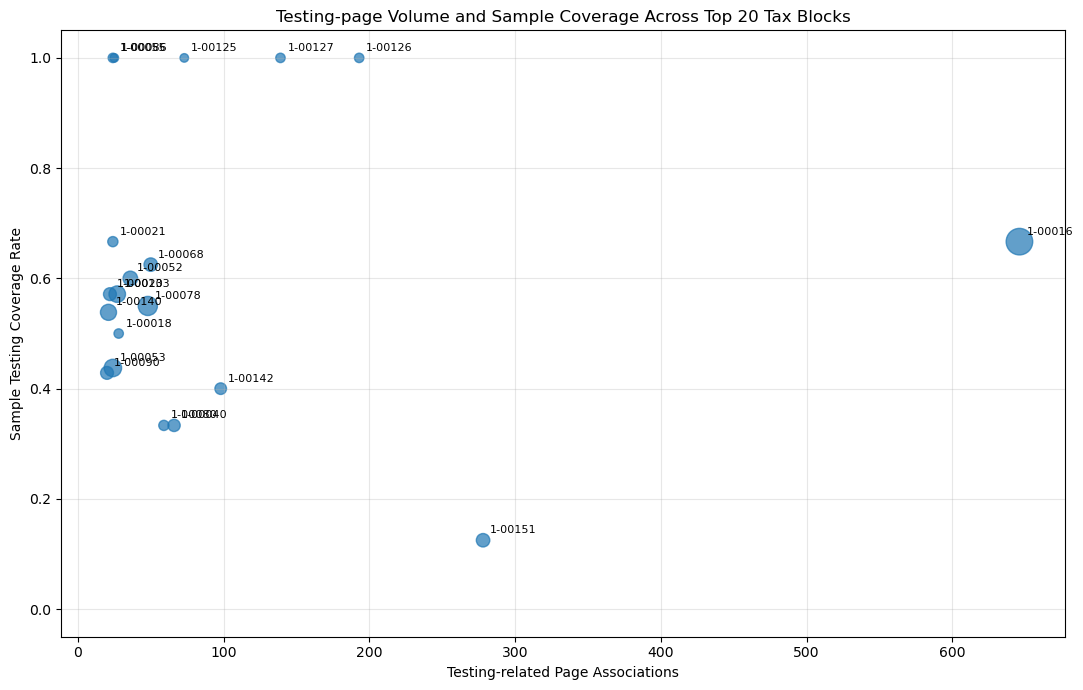

In [10]:
# Select the 20 Tax Blocks with the highest testing-page counts
top_blocks = (
    block_testing_summary
    .nlargest(20, "total_test_pages")
    .copy()
)

fig, ax = plt.subplots(figsize=(11, 7))

scatter = ax.scatter(
    top_blocks["total_test_pages"],
    top_blocks["testing_coverage_rate"],
    s=30 + top_blocks["n_buildings"] * 8,
    alpha=0.7
)

# Label each Tax Block
for _, row in top_blocks.iterrows():
    ax.annotate(
        row["verified_tax_block"],
        (
            row["total_test_pages"],
            row["testing_coverage_rate"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("Testing-related Page Associations")
ax.set_ylabel("Sample Testing Coverage Rate")
ax.set_ylim(-0.05, 1.05)

ax.set_title(
    "Testing-page Volume and Sample Coverage "
    "Across Top 20 Tax Blocks"
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()